# 02 · Baseline → QLoRA → Avaliação → Publicação no Hugging Face

Runtime: **GPU T4** (Colab gratuito). Modelo base: `Qwen/Qwen2.5-1.5B-Instruct` (troque por `Qwen2.5-0.5B-Instruct` se faltar memória).

Fluxo: carregar modelo em 4-bit (NF4) → avaliar **antes** (zero-shot) → treinar adaptador LoRA → avaliar **depois** → comparar com baseline clássico (TF-IDF) → publicar.

Antes de rodar, coloque a pasta `data/` (do notebook 01) no Colab, direto ou via Drive.

In [34]:
!pip -q install peft bitsandbytes accelerate datasets tabulate
# Não usamos -U no torch/transformers para não trocar o build de GPU do Colab.
# Se aparecer erro com `dtype=` em from_pretrained, rode: !pip -q install -U transformers e reinicie o runtime.

In [35]:
# Opcional: monte o Drive se os dados estão lá (descomente)
from google.colab import drive
drive.mount("/content/drive", force_remount=True)
!cp -r /content/drive/MyDrive/colab_notebooks/projeto_1-fine_tuning_com_qlora/data .
!ls data


Mounted at /content/drive
labeler.txt  test.jsonl  train.jsonl  val.jsonl


In [36]:
import json, re, os, torch, numpy as np, pandas as pd
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig,
                          TrainingArguments, Trainer, set_seed)
from sklearn.metrics import f1_score, accuracy_score

set_seed(42)
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
ASPECTS = ["produto", "entrega", "atendimento"]
LABELS = ["positivo", "negativo", "neutro", "ausente"]
DATA_DIR = "data"   # se enviou o data.zip e descompactou
# DATA_DIR = "/content/drive/MyDrive/ifood_qlora/data"   # se copiou para o Drive (monte o Drive antes)

def read_jsonl(p): return [json.loads(l) for l in open(p, encoding="utf-8")]
train, val, test = [read_jsonl(f"{DATA_DIR}/{s}.jsonl") for s in ["train", "val", "test"]]
print(len(train), len(val), len(test), torch.cuda.get_device_name(0))

2400 300 300 Tesla T4


In [37]:
SYSTEM = """Você classifica avaliações de clientes de e-commerce brasileiro por aspecto.
Aspectos: produto (qualidade/estado do item), entrega (prazo/transporte), atendimento (vendedor/suporte/troca).
Valores: positivo, negativo, neutro, ausente (aspecto não mencionado).
Responda somente com JSON: {"produto":"...","entrega":"...","atendimento":"..."}"""

def build_messages(text):
    return [{"role": "system", "content": SYSTEM}, {"role": "user", "content": text}]

def target(row):
    return json.dumps({a: row[a] for a in ASPECTS}, ensure_ascii=False, separators=(",", ":"))

tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"   # geração em batch; o collator de treino faz padding à direita manualmente

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)  # T4 não tem bf16
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb,
                                             device_map={"": 0}, dtype=torch.float16)
print(f"{torch.cuda.memory_allocated()/1e9:.2f} GB")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

3.34 GB


## Avaliação (funções)

Métricas: **JSON válido (%)**, **F1 macro por aspecto**, **acurácia por aspecto**, **exact match** (3 aspectos corretos) e **F1 de detecção de menção** (o aspecto aparece ou não, independente da polaridade). Saída inválida conta como erro.

In [38]:
@torch.no_grad()
def predict(m, texts, bs=16, max_new_tokens=40):
    m.eval(); m.config.use_cache = True
    order = np.argsort([len(t) for t in texts]); outs = [None] * len(texts)
    for i in range(0, len(texts), bs):
        idx = order[i:i + bs]
        prompts = [tok.apply_chat_template(build_messages(texts[j]), tokenize=False, add_generation_prompt=True) for j in idx]
        enc = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(m.device)
        gen = m.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, temperature=None,
                         top_p=None, top_k=None, repetition_penalty=1.0, pad_token_id=tok.pad_token_id)
        dec = tok.batch_decode(gen[:, enc.input_ids.shape[1]:], skip_special_tokens=True)
        for j, d in zip(idx, dec): outs[j] = d
    return outs

def parse(out):
    mt = re.search(r"\{.*?\}", out, re.S)
    if not mt: return None
    try: d = json.loads(mt.group(0))
    except Exception: return None
    if set(d) != set(ASPECTS) or any(d[a] not in LABELS for a in ASPECTS): return None
    return d

def evaluate(raw, gold, name):
    parsed = [parse(o) for o in raw]
    res = {"modelo": name, "json_valido": float(np.mean([p is not None for p in parsed]))}
    f1s, hit, men_y, men_p = [], [], [], []
    for a in ASPECTS:
        y = [r[a] for r in gold]; p = [(x[a] if x else "invalido") for x in parsed]
        labs = [l for l in LABELS if l in set(y)]
        res[f"f1_{a}"] = f1_score(y, p, labels=labs, average="macro", zero_division=0)
        res[f"acc_{a}"] = accuracy_score(y, p)
        f1s.append(res[f"f1_{a}"]); hit.append(np.array(y) == np.array(p))
        men_y += [v != "ausente" for v in y]; men_p += [v not in ("ausente", "invalido") for v in p]
    res["f1_macro_medio"] = float(np.mean(f1s))
    res["exact_match"] = float(np.mean(np.all(hit, axis=0)))
    res["f1_mencao"] = f1_score(men_y, men_p, zero_division=0)
    return res

test_texts = [r["text"] for r in test]

## 1) Antes: baseline zero-shot (modelo base quantizado, sem adaptador)

In [39]:
raw_base = predict(model, test_texts)
res_base = evaluate(raw_base, test, "Qwen2.5-1.5B zero-shot")
print(json.dumps(res_base, indent=1, ensure_ascii=False))
print(raw_base[:3])

{
 "modelo": "Qwen2.5-1.5B zero-shot",
 "json_valido": 0.96,
 "f1_produto": 0.5751917276201036,
 "acc_produto": 0.6933333333333334,
 "f1_entrega": 0.5223711236407572,
 "acc_entrega": 0.68,
 "f1_atendimento": 0.31920675848074637,
 "acc_atendimento": 0.48,
 "f1_macro_medio": 0.47225653658053574,
 "exact_match": 0.26666666666666666,
 "f1_mencao": 0.7582515611061552
}
['{"produto":"negativo","entrega":"negativo","atendimento":"negativo"}', '```json\n{"produto":"negativo","entrega":"ausente","atendimento":"ausente"}\n```', '{"produto":"positivo","entrega":"positivo","atendimento":"ausente"}']


## 2) Baseline clássico: TF-IDF + Regressão Logística (referência de custo-benefício)

In [40]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr, Xte = vec.fit_transform([r["text"] for r in train]), vec.transform(test_texts)
preds = {a: LogisticRegression(max_iter=2000, class_weight="balanced")
            .fit(Xtr, [r[a] for r in train]).predict(Xte) for a in ASPECTS}
raw_tfidf = [json.dumps({a: preds[a][i] for a in ASPECTS}, ensure_ascii=False) for i in range(len(test))]
res_tfidf = evaluate(raw_tfidf, test, "TF-IDF + LogReg")
print(json.dumps(res_tfidf, indent=1, ensure_ascii=False))

{
 "modelo": "TF-IDF + LogReg",
 "json_valido": 1.0,
 "f1_produto": 0.6900963888134672,
 "acc_produto": 0.7666666666666667,
 "f1_entrega": 0.6039625603749839,
 "acc_entrega": 0.8033333333333333,
 "f1_atendimento": 0.4659464688810061,
 "acc_atendimento": 0.74,
 "f1_macro_medio": 0.5866684726898191,
 "exact_match": 0.4866666666666667,
 "f1_mencao": 0.8378378378378378
}


## 3) Treino QLoRA

Decisões:
- **Loss só na resposta** (tokens do prompt mascarados com `-100`): o modelo aprende a classificar, não a copiar o prompt.
- **LoRA r=16, alpha=32** em todas as projeções lineares (atenção + MLP).
- `fp16` (T4 não suporta bf16), `paged_adamw_8bit`, gradient checkpointing.

In [41]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

MAX_LEN = 512
def encode(row):
    prompt = tok.apply_chat_template(build_messages(row["text"]), tokenize=False, add_generation_prompt=True)
    p = tok(prompt, add_special_tokens=False)["input_ids"]
    a = tok(target(row) + tok.eos_token, add_special_tokens=False)["input_ids"]   # eos = <|im_end|>
    ids = (p + a)[:MAX_LEN]; labels = ([-100] * len(p) + a)[:MAX_LEN]
    return {"input_ids": ids, "labels": labels}

ds_tr = Dataset.from_list([encode(r) for r in train])
ds_va = Dataset.from_list([encode(r) for r in val])
print(len(ds_tr), max(len(x) for x in ds_tr["input_ids"]))

def collate(batch):
    m = max(len(b["input_ids"]) for b in batch)
    pad = tok.pad_token_id
    return {
        "input_ids": torch.tensor([b["input_ids"] + [pad] * (m - len(b["input_ids"])) for b in batch]),
        "attention_mask": torch.tensor([[1] * len(b["input_ids"]) + [0] * (m - len(b["input_ids"])) for b in batch]),
        "labels": torch.tensor([b["labels"] + [-100] * (m - len(b["labels"])) for b in batch]),
    }

model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
                  target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
model = get_peft_model(model, lora)
model.print_trainable_parameters()

2400 216
trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


In [42]:
import math
EPOCHS, BS, ACC = 2, 8, 2
total_steps = math.ceil(len(ds_tr) / (BS * ACC)) * EPOCHS
warmup = max(1, int(0.03 * total_steps))
print(f"passos totais: {total_steps} | warmup: {warmup}")

args = TrainingArguments(
    output_dir="out", num_train_epochs=EPOCHS, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=warmup,
    per_device_train_batch_size=BS, per_device_eval_batch_size=BS, gradient_accumulation_steps=ACC,
    fp16=True, optim="paged_adamw_8bit", gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=10, eval_strategy="steps", eval_steps=50, save_strategy="steps", save_steps=50,
    save_total_limit=2, load_best_model_at_end=True, metric_for_best_model="eval_loss",
    report_to="none", seed=42,
)
model.config.use_cache = False
trainer = Trainer(model=model, args=args, train_dataset=ds_tr, eval_dataset=ds_va, data_collator=collate)
trainer.train()

passos totais: 300 | warmup: 9


Step,Training Loss,Validation Loss
50,0.077318,0.073744
100,0.060701,0.063074
150,0.068549,0.059365
200,0.033606,0.053959
250,0.028801,0.051843
300,0.037674,0.050748


TrainOutput(global_step=300, training_loss=0.05489495724439621, metrics={'train_runtime': 1143.6531, 'train_samples_per_second': 4.197, 'train_steps_per_second': 0.262, 'total_flos': 6737170821636096.0, 'train_loss': 0.05489495724439621, 'epoch': 2.0})

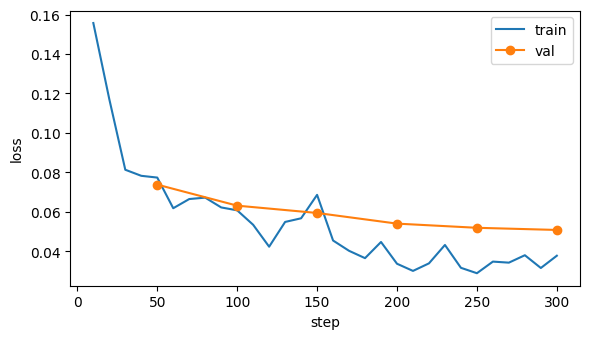

In [43]:
# Curva de loss (guarde a imagem para o README)
import matplotlib.pyplot as plt
h = pd.DataFrame(trainer.state.log_history)
plt.figure(figsize=(6, 3.5))
plt.plot(h.dropna(subset=["loss"]).step, h.dropna(subset=["loss"]).loss, label="train")
plt.plot(h.dropna(subset=["eval_loss"]).step, h.dropna(subset=["eval_loss"]).eval_loss, "o-", label="val")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.tight_layout()
os.makedirs("results", exist_ok=True); plt.savefig("results/loss_curve.png", dpi=150); plt.show()

## 4) Depois: avaliação do modelo ajustado

In [44]:
raw_ft = predict(model, test_texts)
res_ft = evaluate(raw_ft, test, "Qwen2.5-1.5B + QLoRA")
table = pd.DataFrame([res_base, res_tfidf, res_ft]).set_index("modelo").round(3)
table.to_csv("results/metricas.csv"); display(table)

,json_valido,f1_produto,acc_produto,f1_entrega,acc_entrega,f1_atendimento,acc_atendimento,f1_macro_medio,exact_match,f1_mencao
modelo,,,,,,,,,,
Qwen2.5-1.5B zero-shot,0.96,0.575,0.693,0.522,0.680,0.319,0.480,0.472,0.267,0.758
TF-IDF + LogReg,1.00,0.690,0.767,0.604,0.803,0.466,0.740,0.587,0.487,0.838
Qwen2.5-1.5B + QLoRA,1.00,0.805,0.877,0.689,0.913,0.577,0.887,0.691,0.733,0.923


In [45]:
# Análise de erros: onde o modelo ajustado ainda erra?
from sklearn.metrics import classification_report
parsed_ft = [parse(o) for o in raw_ft]
for a in ASPECTS:
    print(f"\n=== {a} ===")
    print(classification_report([r[a] for r in test], [(p[a] if p else "invalido") for p in parsed_ft],
                                zero_division=0, digits=3))

errs = [(r["text"], {a: r[a] for a in ASPECTS}, p) for r, p in zip(test, parsed_ft)
        if p is None or any(p[a] != r[a] for a in ASPECTS)]
print(f"\n{len(errs)} erros de {len(test)}")
for t, g, p in errs[:12]: print("-", t[:160], "\n  gold:", g, "\n  pred:", p)


=== produto ===
              precision    recall  f1-score   support

     ausente      0.808     0.881     0.843        67
    negativo      0.903     0.886     0.894       105
      neutro      0.611     0.478     0.537        23
    positivo      0.943     0.952     0.948       105

    accuracy                          0.877       300
   macro avg      0.816     0.799     0.805       300
weighted avg      0.874     0.877     0.874       300


=== entrega ===
              precision    recall  f1-score   support

     ausente      0.921     0.955     0.938       134
    negativo      0.899     0.920     0.909        87
      neutro      0.000     0.000     0.000         2
    positivo      0.971     0.857     0.910        77

    accuracy                          0.913       300
   macro avg      0.698     0.683     0.689       300
weighted avg      0.921     0.913     0.916       300


=== atendimento ===
              precision    recall  f1-score   support

     ausente      0.

## 5) Publicação no Hugging Face

1. Crie um token com permissão de escrita em huggingface.co/settings/tokens.
2. Ajuste `HF_USER` e rode as células. O model card é gerado com as métricas reais.

In [46]:
from huggingface_hub import notebook_login, HfApi
notebook_login()

In [47]:
HF_USER = "thiag8ito"   # <-- ajuste
REPO = f"{HF_USER}/qwen2.5-1.5b-aspectos-ecommerce-ptbr-qlora"

CARD = """---
language: pt
license: apache-2.0
base_model: __BASE__
library_name: peft
pipeline_tag: text-generation
tags: [peft, qlora, lora, portuguese, aspect-based-sentiment-analysis, olist, brazil]
datasets: [olistbr/brazilian-ecommerce]
---

# __REPO__

Adaptador **QLoRA** (LoRA r=16 sobre base 4-bit NF4) de `__BASE__` para **análise de sentimento por aspecto** em avaliações de e-commerce em português do Brasil. Dada uma avaliação, retorna JSON com o sentimento de `produto`, `entrega` e `atendimento`.

## Uso

```python
import torch
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

base = "__BASE__"
tok = AutoTokenizer.from_pretrained(base)
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)
model = AutoModelForCausalLM.from_pretrained(base, quantization_config=bnb, device_map="auto")
model = PeftModel.from_pretrained(model, "__REPO__")

SYSTEM = __SYSTEM__
msgs = [{"role": "system", "content": SYSTEM},
        {"role": "user", "content": "Produto ótimo, mas o pedido atrasou 10 dias e ninguém respondeu."}]
ids = tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt").to(model.device)
out = model.generate(ids, max_new_tokens=40, do_sample=False)
print(tok.decode(out[0][ids.shape[1]:], skip_special_tokens=True))
```

O prompt de sistema deve ser **o mesmo usado no treino** (acima).

## Dados

- Fonte: avaliações do [Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (texto de avaliações reais, 25–400 caracteres, deduplicadas, amostra balanceada por nota).
- Rótulos de treino/validação: **silver**, gerados por um LLM maior (__LABELER__) com guia de anotação fixo.
- Teste: __NTEST__ avaliações **revisadas manualmente** (gold).
- Split: __NTRAIN__ treino / __NVAL__ validação / __NTEST__ teste.

## Treinamento

| Item | Valor |
|---|---|
| Quantização | 4-bit NF4, double quant, compute fp16 |
| LoRA | r=16, alpha=32, dropout=0.05, todas as projeções lineares |
| Otimizador | paged AdamW 8-bit, lr 2e-4 cosine, warmup 3% |
| Batch efetivo | 16 (8 x 2 acumulação) |
| Épocas | 2 |
| Loss | apenas nos tokens da resposta |
| Hardware | GPU T4 (Colab gratuito) |

## Avaliação (conjunto de teste, rótulo humano)

__TABELA__

`f1_*`: F1 macro por aspecto. `exact_match`: três aspectos corretos. `f1_mencao`: detecção de menção do aspecto. Saídas inválidas contam como erro.

## Limitações e riscos

- Domínio: e-commerce (Olist, 2016–2018). **Não foi validado em delivery de comida**; para esse uso, ajuste com dados do domínio.
- Rótulos de treino são silver: o modelo herda os vieses e erros do LLM anotador.
- Ironia, sarcasmo e avaliações mistas são pontos fracos conhecidos.
- Classe `neutro` é rara; as métricas nela têm alta variância.
- Avaliações podem conter dados pessoais não removidos; o dataset original é anonimizado pelo Olist.
- Modelo de apoio à análise; não usar para decisões automáticas sobre pessoas ou lojistas sem revisão humana.

## Reprodução

Código e notebooks: __CODE_URL__
"""
labeler = open(f"{DATA_DIR}/labeler.txt").read().strip() if os.path.exists(f"{DATA_DIR}/labeler.txt") else "um LLM maior"
card = (CARD.replace("__BASE__", MODEL_ID).replace("__REPO__", REPO).replace("__SYSTEM__", json.dumps(SYSTEM, ensure_ascii=False))
        .replace("__LABELER__", labeler).replace("__NTRAIN__", str(len(train))).replace("__NVAL__", str(len(val)))
        .replace("__NTEST__", str(len(test))).replace("__TABELA__", table.to_markdown())
        .replace("__CODE_URL__", "https://github.com/SEU_USUARIO/ifood-qlora-aspectos"))
open("README_model_card.md", "w").write(card)

4567

In [48]:
api = HfApi()
api.create_repo(REPO, exist_ok=True)
model.push_to_hub(REPO)            # só o adaptador (alguns MB)
tok.push_to_hub(REPO)
api.upload_file(path_or_fileobj="README_model_card.md", path_in_repo="README.md", repo_id=REPO)
api.upload_file(path_or_fileobj="results/loss_curve.png", path_in_repo="loss_curve.png", repo_id=REPO)
print(f"https://huggingface.co/{REPO}")

README.md:   0%|          | 0.00/4.54k [00:00<?, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   0%|          | 45.7kB / 73.9MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/4.55k [00:00<?, ?B/s]

... (2 outputs left out)

  ...mp6lu3nmp3/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


https://huggingface.co/thiag8ito/qwen2.5-1.5b-aspectos-ecommerce-ptbr-qlora


## 6) Teste de ponta a ponta: carregando do Hub como um usuário externo

In [49]:
from peft import PeftModel
del model, trainer; torch.cuda.empty_cache()
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb, device_map={"": 0}, dtype=torch.float16)
m2 = PeftModel.from_pretrained(base, REPO)
exemplos = ["Chegou rápido e o produto é excelente, recomendo!",
            "Comprei e nunca recebi, o vendedor não responde minhas mensagens.",
            "Produto ok, mas a entrega demorou muito."]
for t, o in zip(exemplos, predict(m2, exemplos)): print(t, "->", o)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

adapter_model.safetensors: reconstructing file:   0%|          |  0.00B / 73.9MB            

adapter_model.safetensors: downloading bytes:           |  0.00B            

Chegou rápido e o produto é excelente, recomendo! -> {"produto":"positivo","entrega":"positivo","atendimento":"ausente"}
Comprei e nunca recebi, o vendedor não responde minhas mensagens. -> {"produto":"ausente","entrega":"negativo","atendimento":"negativo"}
Produto ok, mas a entrega demorou muito. -> {"produto":"positivo","entrega":"negativo","atendimento":"ausente"}


In [50]:
!pip freeze | grep -E "transformers|peft|bitsandbytes|accelerate|torch"

accelerate==1.15.0
bitsandbytes==0.50.2
peft==0.21.2
sentence-transformers==5.7.0
torch==2.11.0+cu130
torchao==0.10.0
torchaudio==2.11.0+cu130
torchcodec==0.11.0+cu130
torchdata==0.11.0
torchsummary==1.5.1
torchtune==0.6.1
torchvision==0.26.0+cu130
transformers==5.22.0
